# Forecasting With Many Predictors: Ridge Regression and Gradient Boosting

| Key              | Value |
|:-----------------|:------|
| **Course Codes** | BBT 4206 and BFS 4102 |
| **Course Names** | BBT 4206: Business Intelligence II (Week 7-9 of 13)<br>BFS 4102: Advanced Business Data Analytics (Week 1-3 of 13) |
| **Semester**     | September to December 2026 |
| **Lecturer**     | Allan Omondi |
| **Contact**      | aomondi@strathmore.edu |
| **Note**         | The lecture contains both theory and practice.<br/>This notebook forms part of the practice.<br/>It is intended for educational purposes only, and nothing in it is investment advice.<br/>Recommended citation: [BibTex](https://raw.githubusercontent.com/course-files/TimeSeriesForecastingandNeuralNetworks/refs/heads/main/RecommendedCitation.bib) |

## What you will learn in this notebook

By the end of this notebook you should be able to:

1. Build a table of **many predictors** (the stock's own history, volatility, technical indicators, volume, and other markets) for forecasting the next-day return.
2. Explain **look-ahead bias (data leakage)** and detect it with a test.
3. Fit a **Ridge regression** and a **gradient boosting** model, and explain how each one works.
4. Tune hyperparameters **without** touching the test period.
5. Evaluate with **walk-forward validation**, compare with the naive forecast, and test whether the difference is real.
6. Find out **which groups of predictors** add value, and which features the model uses.
7. Produce a forecast with an **uncertainty interval**, and see what a directional edge is worth after trading costs.

**Prerequisites:** Notebooks 1 to 3.

## The Idea

In Notebook 3 the classical models used the stock's own past and, in the last case, seven other markets. They had very little to work with, and they could only combine the inputs **linearly**.

Here we give the model a much richer description of "what the situation is at the close of today", and we allow it to find **non-linear** relationships and **interactions** between predictors, such as "momentum matters only when volatility is low".

We keep the same question as before: **does this beat the naive forecast on days it has never seen?**

## Step 1: Set Up the Notebook

In [1]:
import os
import sys
import subprocess

print("Python interpreter:", sys.executable)
print("Python version    :", sys.version.split()[0])

# Google Colab starts with an empty workspace, so we fetch the lab files first.
# On your own computer this block does nothing.
if "google.colab" in sys.modules and not os.path.exists("tslab"):
    subprocess.run(["git", "clone", "https://github.com/course-files/TimeSeriesForecastingandNeuralNetworks.git"], check=True)
    os.chdir("TimeSeriesForecastingandNeuralNetworks")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", "requirements/colab.txt"], check=True)
    print("Colab workspace prepared.")

Python interpreter: C:\Users\aomondi\Documents\GitHub\Teaching\TimeSeriesForecastingandNeuralNetworks\.venv\Scripts\python.exe
Python version    : 3.12.10


In [2]:
import os
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import Ridge, LinearRegression
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.inspection import permutation_importance
from sklearn.preprocessing import StandardScaler

from tslab import config
from tslab.data import load_market_data
from tslab.features import (build_features, make_dataset, check_no_lookahead,
                            FEATURE_GROUPS, ALL_FEATURES)
from tslab.validation import walk_forward_splits, walk_forward_predict, describe_splits
from tslab.metrics import (compare_models, diebold_mariano, dm_verdict, directional_accuracy_test,
                           out_of_sample_r2, simple_backtest, backtest_summary)
from tslab.plots import plot_walk_forward_layout, plot_price_forecasts

import warnings
warnings.filterwarnings("ignore")

%matplotlib inline
plt.rcParams["figure.figsize"] = (12, 5)

## Step 2: The Table of Predictors

The function `build_features` in `tslab/features.py` turns the raw market table into about fifty predictors, in six groups. Open that file and read it now. Every feature is a few lines and has a comment saying what it measures.

The rule that governs every line of that file is:

> **A feature in row t may use only information known at the close of day t.**

In [3]:
frame = load_market_data()
dataset = make_dataset(frame, horizon=1)

# The last row has features but no target yet (tomorrow has not happened). Keep it aside for a real forecast.
latest_row = dataset.iloc[[-1]]
dataset = dataset.dropna(subset=["target_return"])

print("Rows in the modelling table:", len(dataset))
print("Number of predictors       :", len(ALL_FEATURES))
print("First day                  :", dataset.index[0].date())
print("Last day with a known target:", dataset.index[-1].date())

Loaded 2953 trading days of NVDA, 2015-01-02 to 2026-09-30, with 7 predictor series.
Rows in the modelling table: 2753
Number of predictors       : 47
First day                  : 2015-10-16
Last day with a known target: 2026-09-29


In [4]:
summary = pd.DataFrame({
    "Number of features": {group: len(names) for group, names in FEATURE_GROUPS.items()},
    "Examples": {group: ", ".join(names[:4]) + (", ..." if len(names) > 4 else "") for group, names in FEATURE_GROUPS.items()},
})
summary

,Number of features,Examples
returns,9,"ret_lag1, ret_lag2, ret_lag3, ret_lag4, ..."
volatility,6,"vol_5d, vol_21d, vol_63d, vol_ratio, ..."
technical,9,"rsi_14, macd_hist, bb_percent_b, bb_width, ..."
volume,1,volume_rel_20d
other_markets,15,"SP500_ret_1d, SP500_ret_5d, TECH_ret_1d, TECH_..."
calendar,7,"is_mon, is_tue, is_wed, is_thu, ..."


| Group | The question it answers |
|:------|:------------------------|
| **returns** | What has the price done over the last day, week, month and quarter? (momentum and reversal) |
| **volatility** | How violently has it been moving? |
| **technical** | Where is the price relative to its recent average and range? (RSI, MACD, Bollinger Bands, distance from moving averages, overnight gap) |
| **volume** | Is trading unusually heavy or light? |
| **other_markets** | What are the market, the sector, fear, interest rates, the dollar, oil and gold doing? |
| **calendar** | Which weekday and month is it? |

Remember the target. For every row, `target_return` is `log(close tomorrow / close today)`. We predict it, and then turn the prediction into a price with `close today * exp(predicted return)`.

In [5]:
dataset[["close", "target_return", "target_close"]].tail(3)

,close,target_return,target_close
Date,,,
2026-09-25,225.070007,0.016699,228.860001
2026-09-28,228.860001,-0.007236,227.210007
2026-09-29,227.210007,0.005136,228.380005


## Step 3: Look-Ahead Bias, the Silent Killer

**Look-ahead bias** (also called data leakage) means that information from the future has slipped into the inputs of a model. A model with leakage looks fantastic in your notebook, and fails the day it meets real data. It is the most expensive mistake in financial machine learning, and it is easy to make without noticing.

### 3.1 The truncation test

If a feature uses only the past, then computing it from a table that **stops at day t** must give the same value for day t as computing it from the **full** table. The function `check_no_lookahead` cuts the data at several random dates and compares. Run it on our features.

In [6]:
check_no_lookahead(frame, n_checks=8)
print("PASSED: none of the features changes when the future is removed.")

PASSED: none of the features changes when the future is removed.


### 3.2 What a leak looks like

Now we deliberately add a feature that peeks at the future, to see what the test finds. A **centred** rolling mean uses a window that is centred on today: it includes the two days after today. This is easy to write by accident, because `center=True` is a tempting option in pandas.

In [7]:
def features_with_a_leak(market):
    table = build_features(market)
    table["centred_average_gap"] = np.log(market["Close"].rolling(5, center=True).mean() / market["Close"])
    return table

try:
    check_no_lookahead(frame, feature_function=features_with_a_leak, n_checks=8)
except AssertionError as problem:
    print("The test caught it:")
    print(problem)

The test caught it:
Look-ahead bias detected on 2025-01-21: these features changed when the future was removed: ['centred_average_gap']


### 3.3 What the leak does to the results

How much does a leak flatter a model? We train the same Ridge regression on the first 70 percent of the rows and test it on the last 30 percent, once with the honest features and once with the leaky feature added.

In [8]:
leaky_table = features_with_a_leak(frame).reindex(dataset.index)
X_honest = dataset[ALL_FEATURES]
X_leaky = pd.concat([X_honest, leaky_table[["centred_average_gap"]]], axis=1).dropna()
y = dataset["target_return"]

cut = int(len(X_honest) * 0.7)

def holdout_r2(X):
    X = X.loc[X.index.intersection(y.index)]
    scaler = StandardScaler().fit(X.iloc[:cut])
    model = Ridge(alpha=10).fit(scaler.transform(X.iloc[:cut]), y.loc[X.index].iloc[:cut])
    prediction = model.predict(scaler.transform(X.iloc[cut:]))
    return out_of_sample_r2(y.loc[X.index].iloc[cut:], prediction)

print(f"Out-of-sample R2 with honest features: {holdout_r2(X_honest):8.4f}")
print(f"Out-of-sample R2 with the leaky feature: {holdout_r2(X_leaky):8.4f}")

Out-of-sample R2 with honest features:  -0.0112
Out-of-sample R2 with the leaky feature:   0.7854


The leaky feature lifts the R2 from roughly zero to something that looks like a breakthrough, even though it holds only two days of the future. **A very good result in financial forecasting is a reason to suspect a bug before you celebrate.**

### 3.4 Other leaks to remember

| Leak | How it happens | Where this lab prevents it |
|:-----|:---------------|:---------------------------|
| **Scaling on all the data** | Fitting `StandardScaler` or `MinMaxScaler` on the whole dataset gives the training step the future mean and spread. | `walk_forward_predict` fits the scaler on each training block only. |
| **Shuffled splits** | `train_test_split(shuffle=True)` trains on the future and tests on the past. | We never shuffle across time. |
| **Same-day predictors** | Using today's market move to forecast today's stock move. | Every predictor is known at the close of day t, and the target is for day t+1. |
| **Backward filling** | `fillna(method="bfill")` copies a future value into the past. | `load_market_data` only fills forward, for at most three days. |
| **Tuning on the test set** | Choosing the hyperparameters that score best on the test data. | We tune on the first training block only (Step 6). |
| **Overlapping labels** | For a multi-day target, the last training labels overlap the first test days. | The `gap` argument in `walk_forward_splits` (used in Notebook 7). |

## Step 4: Walk-Forward Validation

We use the same settings as in Notebook 3 (a first training block of 1000 days, then test blocks of 63 days with an expanding training window), so that every model in the lab is scored on the same days.

Number of folds: 28


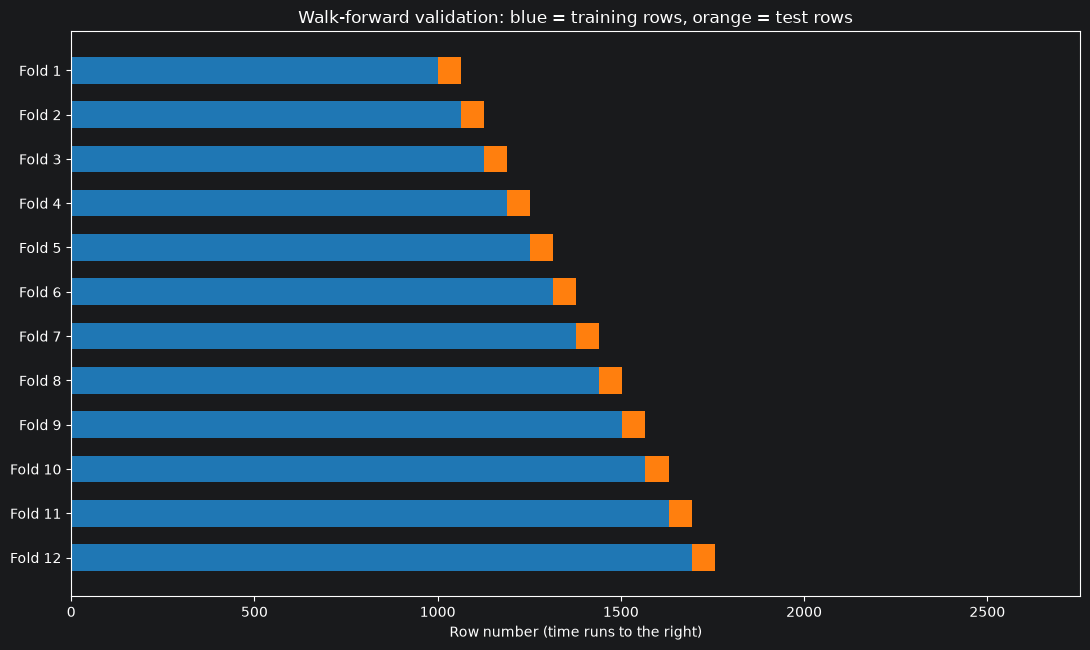

In [9]:
X = dataset[ALL_FEATURES]
y = dataset["target_return"]

splits = list(walk_forward_splits(len(dataset), config.INITIAL_TRAIN, config.TEST_SIZE))
print("Number of folds:", len(splits))
plot_walk_forward_layout(splits, len(dataset))

In [10]:
describe_splits(splits, dataset.index).tail(3)

,train_rows,train_from,train_to,test_rows,test_from,test_to
fold,,,,,,
26,2575,2015-10-16,2026-01-13,63,2026-01-14,2026-04-15
27,2638,2015-10-16,2026-04-15,63,2026-04-16,2026-07-16
28,2701,2015-10-16,2026-07-16,52,2026-07-17,2026-09-29


## Step 5: The Models

### 5.1 Ridge regression, the linear model for many predictors

Ordinary linear regression on 50 predictors will overfit: with that many inputs it can always find some combination that explains the training data by chance. **Ridge regression** adds a penalty on the size of the coefficients, controlled by `alpha`. A larger alpha shrinks the coefficients towards zero and makes the model simpler and more cautious. Because the penalty depends on the size of the coefficients, the features must be on the same scale, which is why `walk_forward_predict` standardises them (using the training block only).

### 5.2 Gradient boosting, the non-linear model

Gradient boosting builds a model as a **sum of many small decision trees**, one at a time:

1. Start with a simple prediction (the average return).
2. Compute the **errors** of the current model.
3. Fit a small tree to predict those errors, and add a **fraction** of it to the model (the fraction is the `learning_rate`).
4. Repeat for `max_iter` rounds. Each new tree corrects what the earlier trees got wrong.

The important settings are the ones that **limit** the model, because in finance the signal is faint and the noise is loud:

| Setting | What it does |
|:--------|:-------------|
| `max_depth` | How many questions each tree can ask. Shallow trees (2 to 3) cannot memorise. |
| `learning_rate` | How big each correction is. Small values need more trees but generalise better. |
| `max_iter` | The number of trees. |
| `min_samples_leaf` | The smallest group of days a tree may isolate. A large value stops a tree from reacting to a handful of days. |
| `l2_regularization` | The same shrinking idea as in Ridge. |

Gradient boosting is the most widely used method for tabular financial data, because it handles many predictors of different scales, finds interactions on its own, and does not need the features to be normally distributed. It does **not** know that rows are ordered in time, which is why we supply the lags and rolling statistics ourselves.

## Step 6: Choose Hyperparameters Without Touching the Test Period

If you try ten settings and keep the one that scores best on your test days, your test score is no longer an honest estimate: you chose the winner **because** it was lucky on those days. This is called **selection bias** or tuning on the test set.

The remedy is to tune on data that is **before** the test period, using walk-forward validation inside it. We use only the first 1000 days (the first training block), with an inner walk-forward test (train on 500 days, test on blocks of 100). The winning settings are then **frozen** and used for every fold of the real test.

In [11]:
tuning_X, tuning_y = X.iloc[: config.INITIAL_TRAIN], y.iloc[: config.INITIAL_TRAIN]
inner_splits = list(walk_forward_splits(len(tuning_X), initial_train=500, test_size=100))
print("Tuning folds:", len(inner_splits), "(all inside the first", config.INITIAL_TRAIN, "days)")

def tuning_score(model_factory):
    """Mean squared error of the walk-forward predictions inside the tuning block (lower is better)."""
    predicted = walk_forward_predict(model_factory, tuning_X, tuning_y, inner_splits)
    mask = predicted.notna()
    return float(np.mean((tuning_y[mask] - predicted[mask]) ** 2))

# --- Ridge: the strength of the penalty
ridge_results = {alpha: tuning_score(lambda a=alpha: Ridge(alpha=a)) for alpha in [1, 10, 100, 1000, 10000, 100000]}
best_alpha = min(ridge_results, key=ridge_results.get)
display(pd.Series(ridge_results, name="Tuning MSE").to_frame().T)
print("Chosen Ridge alpha:", best_alpha)

Tuning folds: 5 (all inside the first 1000 days)


,1,10,100,1000,10000,100000
Tuning MSE,0.001063,0.001038,0.00096,0.000878,0.000857,0.000854


Chosen Ridge alpha: 100000


Look at how the score changes as the penalty grows. It improves steadily from `alpha = 1` up to `alpha = 10000`, and then stops improving, because the coefficients have been squeezed so close to zero that there is nothing left to shrink. With a huge `alpha` the forecast is close to the **average return** every day. A very cautious Ridge being the best Ridge is itself a finding. It tells us how little signal the predictors carry for one-day-ahead returns.

In [12]:
# --- Gradient boosting: depth and learning rate
def make_boosting(max_depth=3, learning_rate=0.03, max_iter=200, loss="squared_error", quantile=None):
    return HistGradientBoostingRegressor(
        loss=loss, quantile=quantile,
        max_depth=max_depth, learning_rate=learning_rate, max_iter=max_iter,
        min_samples_leaf=40, l2_regularization=1.0, random_state=config.SEED,
    )

grid = [(depth, rate) for depth in (2, 3, 5) for rate in (0.01, 0.03)]
started = time.time()
boost_results = {combo: tuning_score(lambda c=combo: make_boosting(max_depth=c[0], learning_rate=c[1])) for combo in grid}
print(f"Tuning took {time.time() - started:.0f} seconds")

boost_table = pd.Series(boost_results, name="Tuning MSE").rename_axis(["max_depth", "learning_rate"]).to_frame()
display(boost_table.round(8))
best_depth, best_rate = min(boost_results, key=boost_results.get)
print("Chosen boosting settings: max_depth =", best_depth, ", learning_rate =", best_rate)

Tuning took 6 seconds


Tuning MSE
max_depth learning_rate            
2         0.01             0.000866
          0.03             0.000897
3         0.01             0.000872
          0.03             0.000919
5         0.01             0.000885
          0.03             0.000940

Chosen boosting settings: max_depth = 2 , learning_rate = 0.01


Look at how little the scores differ between the settings. When the signal is weak, tuning cannot rescue a model. Picking the smaller (more cautious) model in a near tie is sensible.

## Step 7: Walk-Forward Test

Now the real test. For every fold, a **new** model is fitted on all the history so far and used to predict the next 63 days. The settings are the frozen ones from Step 6.

In [13]:
predictions = {}

started = time.time()
predictions["Ridge"] = walk_forward_predict(lambda: Ridge(alpha=best_alpha), X, y, splits)
print(f"Ridge finished in {time.time() - started:.1f} seconds")

started = time.time()
predictions["Gradient boosting"] = walk_forward_predict(
    lambda: make_boosting(max_depth=best_depth, learning_rate=best_rate), X, y, splits)
print(f"Gradient boosting finished in {time.time() - started:.1f} seconds")

Ridge finished in 0.1 seconds
Gradient boosting finished in 5.4 seconds


In [14]:
scores = compare_models(dataset, predictions)
scores.round(4)

,RMSE ($),MAE ($),MAPE (%),Directional accuracy,Out-of-sample R2 (returns)
Naive (no change),2.6779,1.5131,2.3472,NaN,0.0000
Ridge,2.6759,1.5077,2.3386,0.5431,0.0055
Gradient boosting,2.6729,1.5109,2.3402,0.5317,0.0025


Read the table as you did in Notebook 3: compare the RMSE with the naive row first, then the out-of-sample R2, then the directional accuracy.

Now ask whether any gap is **real**. We run the Diebold-Mariano test against the naive forecast, and a binomial test of the directional accuracy against a coin toss.

In [15]:
scored_rows = pd.concat(predictions, axis=1).dropna().index
actual = dataset.loc[scored_rows, "target_return"]

rows = []
for name, series in predictions.items():
    statistic, p_dm = diebold_mariano(actual, series.loc[scored_rows], np.zeros(len(scored_rows)))
    hit_rate, p_dir = directional_accuracy_test(actual, series.loc[scored_rows])
    rows.append({"Model": name,
                 "DM statistic vs naive": statistic, "DM p-value": p_dm, "Verdict": dm_verdict(statistic, p_dm),
                 "Hit rate": hit_rate, "Hit rate p-value (vs 50%)": p_dir})
pd.DataFrame(rows).set_index("Model").round(4)

,DM statistic vs naive,DM p-value,Verdict,Hit rate,Hit rate p-value (vs 50%)
Model,,,,,
Ridge,-1.6689,0.0953,No significant difference,0.5431,0.0003
Gradient boosting,-0.3320,0.7399,No significant difference,0.5317,0.0086


How to read this:

- A **negative** DM statistic with a p-value below 0.05 means the model has a significantly **smaller** squared error than the naive forecast. A positive statistic means that it is worse.
- A hit rate whose p-value is above 0.05 is statistically **indistinguishable from guessing**.

If neither model passes, that is not a failure of your code. It is the honest finding, and the most common one in this field.

### Look at the predictions against the actual returns

If a model had skill, a scatter plot of predicted against actual returns would slope upward. We draw it, together with the fitted line.

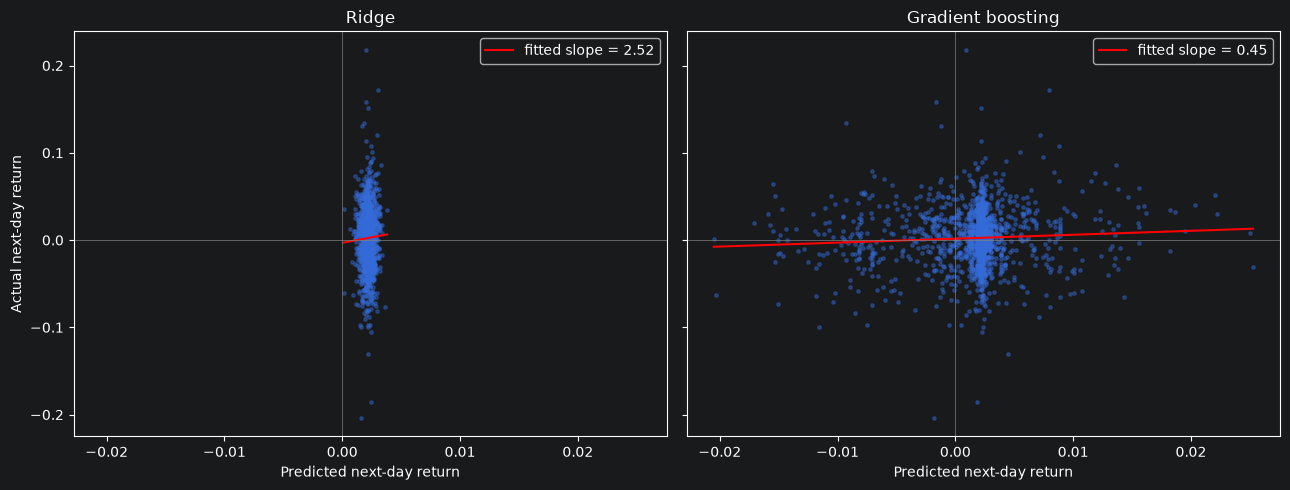

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharex=True, sharey=True)
for ax, name in zip(axes, predictions):
    p = predictions[name].loc[scored_rows]
    ax.scatter(p, actual, s=6, alpha=0.4)
    slope, intercept = np.polyfit(p, actual, 1)
    grid_x = np.linspace(p.min(), p.max(), 50)
    ax.plot(grid_x, slope * grid_x + intercept, color="red", label=f"fitted slope = {slope:.2f}")
    ax.axhline(0, color="grey", linewidth=0.5); ax.axvline(0, color="grey", linewidth=0.5)
    ax.set_title(name); ax.set_xlabel("Predicted next-day return"); ax.legend()
axes[0].set_ylabel("Actual next-day return")
plt.tight_layout(); plt.show()

A model with perfect skill would produce a slope of 1. A model with no skill produces a slope near 0. Notice also that the predicted returns occupy a **narrow** band compared with the actual returns: the model is cautious, because it has learned that most of the movement is unpredictable.

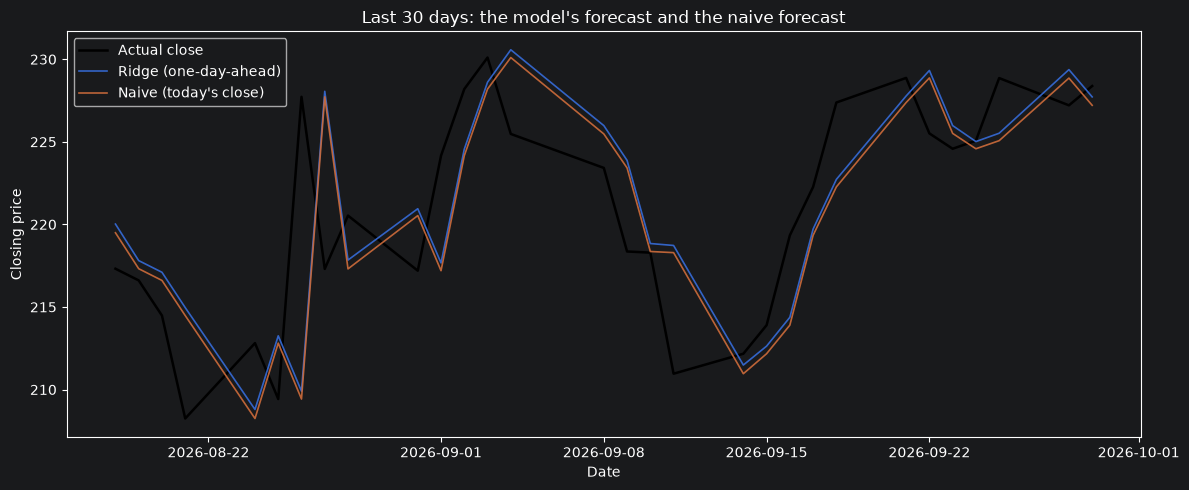

In [17]:
scored = dataset.loc[scored_rows]
best_name = scores.drop(index="Naive (no change)")["Out-of-sample R2 (returns)"].idxmax()
plot_price_forecasts(
    dates=scored.index, actual=scored["target_close"].values,
    forecasts={f"{best_name} (one-day-ahead)": (scored["close"] * np.exp(predictions[best_name].loc[scored_rows])).values,
               "Naive (today's close)": scored["close"].values},
    title="Last 30 days: the model's forecast and the naive forecast", last_n=30)

## Step 8: Which Predictors Matter? (Feature Group Ablation)

We now ask the central question of this lab: **do the extra predictors help?** An **ablation** study answers it. We train the model with different subsets of the predictor groups, and compare the out-of-sample R2.

- **Only this group**: how much can this group do on its own?
- **Without this group**: how much do we lose when we take it away?

To keep the run time short we use Ridge, which is very fast. (You may repeat it with gradient boosting as an exercise.)

In [18]:
def score_features(feature_list, model_factory=lambda: Ridge(alpha=best_alpha)):
    predicted = walk_forward_predict(model_factory, dataset[feature_list], y, splits)
    mask = predicted.notna()
    return out_of_sample_r2(y[mask], predicted[mask])

rows = []
for group, names in FEATURE_GROUPS.items():
    others = [f for f in ALL_FEATURES if f not in names]
    rows.append({"Group": group,
                 "R2 using ONLY this group": score_features(names),
                 "R2 WITHOUT this group": score_features(others)})
ablation = pd.DataFrame(rows).set_index("Group")
all_features_r2 = score_features(ALL_FEATURES)
print(f"R2 with ALL features: {all_features_r2:.5f}")
ablation.round(5)

R2 with ALL features: 0.00547


,R2 using ONLY this group,R2 WITHOUT this group
Group,,
returns,0.00451,0.00536
volatility,0.00436,0.00546
technical,0.00446,0.00541
volume,0.00437,0.00545
other_markets,0.00527,0.00462
calendar,0.00433,0.00548


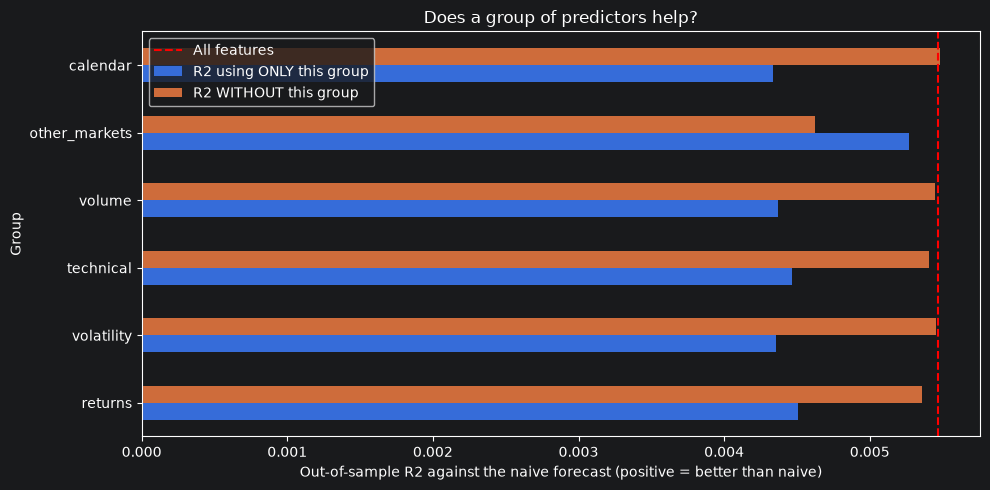

In [19]:
ablation[["R2 using ONLY this group", "R2 WITHOUT this group"]].plot.barh(figsize=(10, 5))
plt.axvline(0, color="black", linewidth=0.8)
plt.axvline(all_features_r2, color="red", linestyle="--", label="All features")
plt.xlabel("Out-of-sample R2 against the naive forecast (positive = better than naive)")
plt.title("Does a group of predictors help?")
plt.legend(); plt.tight_layout(); plt.show()

How to read the chart:

- A bar to the **right** of zero means the model beat the naive forecast. A bar to the **left** means it did worse.
- If removing a group makes the R2 **higher** than the all-features value, that group was adding noise.
- More predictors do not automatically mean a better model. Each additional feature is another chance to fit noise.

Be careful about the size of the numbers. Differences of 0.001 to 0.004 in R2 are tiny. They are well within what a different test period could reverse, so treat the ranking of the groups as a hint, not a result. Write down, in your own words, what your ablation shows about the "other markets" group: the main reason this lab was redesigned.

## Step 9: What Does the Model Actually Use? (Permutation Importance)

**Permutation importance** answers: "if I scramble this feature, so that it carries no information, how much worse do the predictions get?" A large loss means the model relies on the feature. A loss near zero means it does not.

We fit the boosting model on all rows before the last two years, and measure importance on the last two years (about 504 days), which the model has not seen.

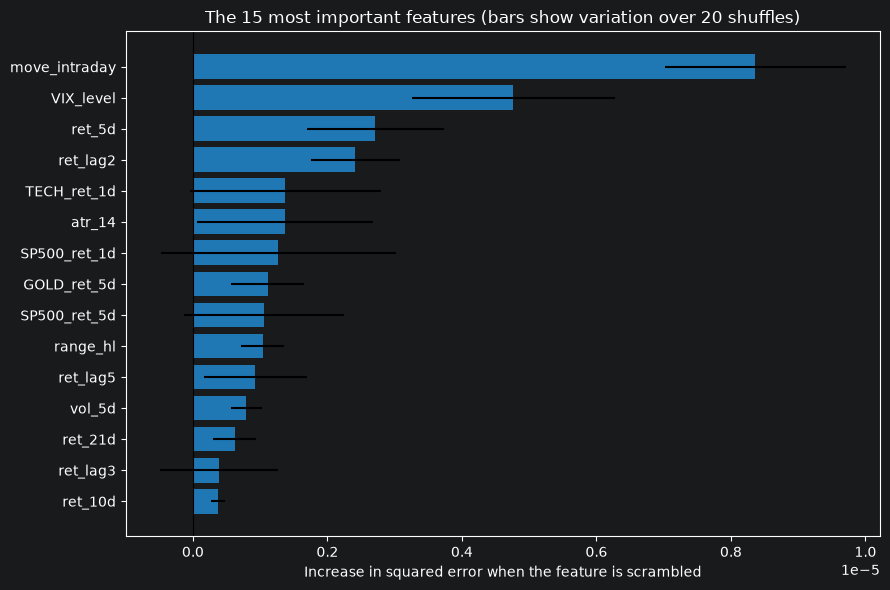

In [20]:
hold = 504
X_fit, y_fit = X.iloc[:-hold], y.iloc[:-hold]
X_test, y_test = X.iloc[-hold:], y.iloc[-hold:]

model = make_boosting(max_depth=best_depth, learning_rate=best_rate).fit(X_fit, y_fit)
result = permutation_importance(model, X_test, y_test, scoring="neg_mean_squared_error",
                                n_repeats=20, random_state=config.SEED)
importance = pd.Series(result.importances_mean, index=ALL_FEATURES).sort_values()
spread = pd.Series(result.importances_std, index=ALL_FEATURES)[importance.index]

top = importance.tail(15)
plt.figure(figsize=(9, 6))
plt.barh(top.index, top.values, xerr=spread[top.index].values, color="tab:blue")
plt.axvline(0, color="black", linewidth=0.8)
plt.xlabel("Increase in squared error when the feature is scrambled")
plt.title("The 15 most important features (bars show variation over 20 shuffles)")
plt.tight_layout(); plt.show()

Interpret this chart with care.

- Importance is measured on one test window. A feature that looks important here may not be on another window.
- If the error bars are as long as the bars themselves, the importance is **not distinguishable from zero**.
- Importance does not prove that a feature **causes** the return to change. It shows only that the model's predictions depend on it.
- If the model has little skill, its "important" features are mainly the ones it has fitted noise to. Importance does not tell you that a model is good; it tells you what a model does.

## Step 10: Forecasts With Uncertainty (Quantile Regression)

A single number, "tomorrow's close will be 191.30", hides how unsure we are. A **prediction interval** gives a range. Gradient boosting can estimate a **quantile** of the return directly by minimising a different loss (the pinball loss). We fit one model for the 10th percentile and another for the 90th, so that the range between them should contain the actual return about **80 percent** of the time.

In [21]:
started = time.time()
q10 = walk_forward_predict(lambda: make_boosting(loss="quantile", quantile=0.10), X, y, splits)
q90 = walk_forward_predict(lambda: make_boosting(loss="quantile", quantile=0.90), X, y, splits)
print(f"Quantile models finished in {time.time() - started:.1f} seconds")

inside = ((y >= q10) & (y <= q90))[q10.notna()]
print(f"Share of days when the actual return fell inside the 10% to 90% range: {inside.mean():.1%}  (target: 80%)")

Quantile models finished in 30.9 seconds
Share of days when the actual return fell inside the 10% to 90% range: 72.9%  (target: 80%)


**Coverage** is the share of the actual outcomes that fall inside the interval. If it is clearly below 80 percent, the model is **overconfident**: its intervals are too narrow. Volatility clustering (Notebook 2) makes this common, because the intervals fitted in calm periods are too narrow for stormy ones.

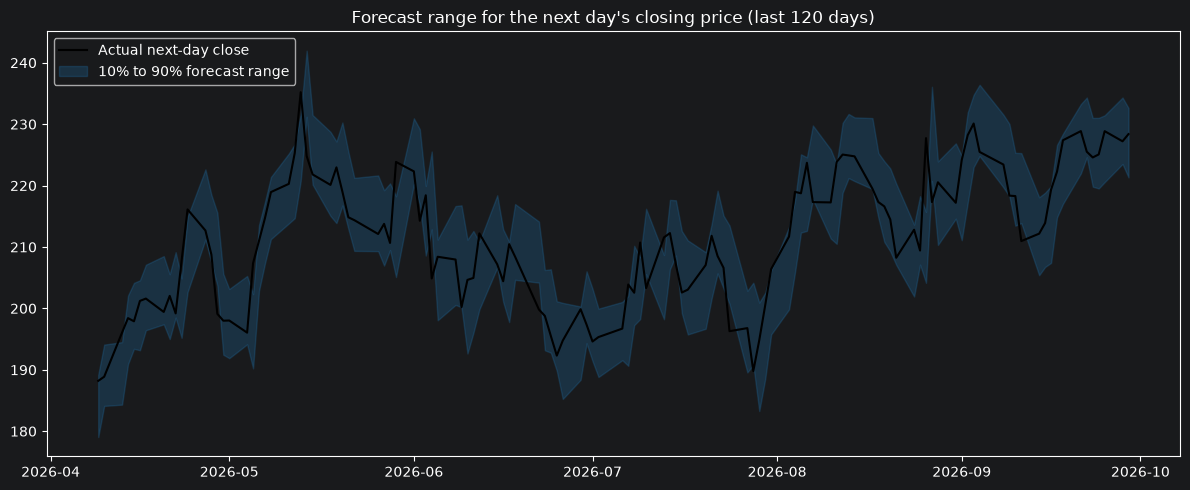

In [22]:
recent = dataset.loc[scored_rows].iloc[-120:]
close_today = recent["close"]
lower_price = close_today * np.exp(q10.loc[recent.index])
upper_price = close_today * np.exp(q90.loc[recent.index])

plt.figure(figsize=(12, 5))
plt.plot(recent.index, recent["target_close"], color="black", label="Actual next-day close")
plt.fill_between(recent.index, lower_price, upper_price, color="tab:blue", alpha=0.25, label="10% to 90% forecast range")
plt.title("Forecast range for the next day's closing price (last 120 days)")
plt.legend(); plt.tight_layout(); plt.show()

## Step 11: What Is a Directional Edge Worth?

Suppose your model predicts the direction correctly 52 percent of the time. Is that a business? We run a simple trading experiment. Each day we hold **+1 unit** if the model predicts a rise and **-1 unit** (a short position) if it predicts a fall. Every time we change position we pay a **transaction cost** in basis points (1 basis point is 0.01 percent).

This is a teaching device, not a trading strategy. It ignores many real frictions (spreads, market impact, borrowing costs for shorting, taxes).

In [23]:
rows = []
curves = {}
actual_returns = dataset.loc[scored_rows, "target_return"].values
for name in predictions:
    for cost in (0, 5, 10):
        daily = simple_backtest(actual_returns, predictions[name].loc[scored_rows].values, cost_bps=cost)
        summary_row = backtest_summary(daily)
        rows.append({"Model": name, "Cost per trade (bp)": cost, **summary_row.round(3).to_dict()})
        if cost in (0, 10):
            curves[f"{name}, cost {cost} bp"] = daily.cumsum().values

buy_and_hold = pd.Series(actual_returns)
rows.append({"Model": "Buy and hold", "Cost per trade (bp)": 0, **backtest_summary(buy_and_hold).round(3).to_dict()})
curves["Buy and hold"] = buy_and_hold.cumsum().values
for name in predictions:
    share_long = (predictions[name].loc[scored_rows] > 0).mean()
    print(f"{name}: long on {share_long:.0%} of the days")
display(pd.DataFrame(rows).set_index(["Model", "Cost per trade (bp)"]))

Ridge: long on 100% of the days
Gradient boosting: long on 82% of the days


Annual return  Annual volatility  \
Model             Cost per trade (bp)                                     
Ridge             0                            0.568              0.509   
                  5                            0.568              0.509   
                  10                           0.568              0.509   
Gradient boosting 0                            0.526              0.509   
                  5                            0.485              0.509   
                  10                           0.445              0.509   
Buy and hold      0                            0.568              0.509   

                                       Sharpe ratio  
Model             Cost per trade (bp)                
Ridge             0                           1.116  
                  5                           1.116  
                  10                          1.116  
Gradient boosting 0                           1.033  
                  5                           0.954  
                  10                          0.874  
Buy and hold      0                           1.116

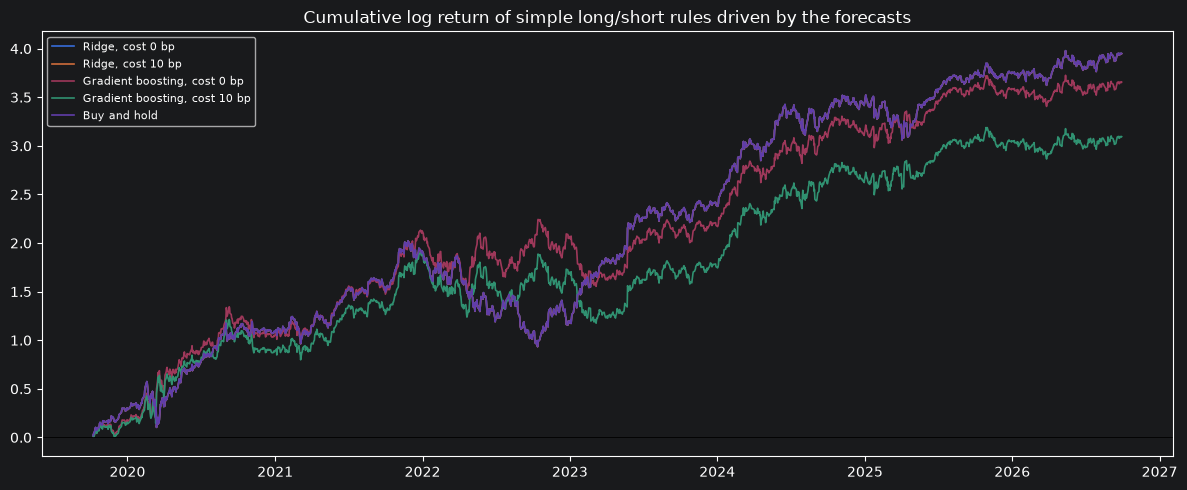

In [24]:
plt.figure(figsize=(12, 5))
for label, values in curves.items():
    plt.plot(scored_rows, values, label=label, linewidth=1.2)
plt.axhline(0, color="black", linewidth=0.6)
plt.title("Cumulative log return of simple long/short rules driven by the forecasts")
plt.legend(fontsize=8); plt.tight_layout(); plt.show()

Before reading the table, look at the share of days on which each model is long (it is printed above the table). A model whose forecast is almost always positive behaves like buy-and-hold with a few exceptions, and its results are then not evidence of forecasting skill. Three things to examine in the table and chart:

1. **Do the strategies beat buy-and-hold** for this stock, which rose over most of the period?
2. How quickly does the result **deteriorate as costs rise**? A forecast that trades every day pays the cost every day it changes its mind.
3. Is the **Sharpe ratio** (the average return per unit of risk) high enough to take seriously? A ratio below about 0.5 is hard to distinguish from luck over a few years.

A statistically weak edge, plus costs, usually leaves nothing. This is why professional quantitative teams spend far more effort on **costs, risk and validation** than on finding new models.

## Step 12: Make a Real Forecast for Tomorrow

The final row of the table has features for the last trading day but no target yet. The final model, fitted on **all** the rows with a known target, predicts the next-day return, and the 10th and 90th percentile models give the range.

In [25]:
final_scaler = StandardScaler().fit(X)
final_point = make_boosting(max_depth=best_depth, learning_rate=best_rate).fit(final_scaler.transform(X), y)
final_q10 = make_boosting(loss="quantile", quantile=0.10).fit(final_scaler.transform(X), y)
final_q90 = make_boosting(loss="quantile", quantile=0.90).fit(final_scaler.transform(X), y)

today = final_scaler.transform(latest_row[ALL_FEATURES])
last_close = float(latest_row["close"].iloc[0])
next_date = latest_row.index[0] + pd.offsets.BDay(1)

forecast = pd.Series({
    "Last close": last_close,
    "Forecast for the next trading day": last_close * float(np.exp(final_point.predict(today))[0]),
    "10% quantile": last_close * float(np.exp(final_q10.predict(today))[0]),
    "90% quantile": last_close * float(np.exp(final_q90.predict(today))[0]),
})
print(f"Data up to {latest_row.index[0].date()}; forecast for {next_date.date()}")
forecast.round(2)

Data up to 2026-09-30; forecast for 2026-10-01


Last close                           228.38
Forecast for the next trading day    228.83
10% quantile                         223.45
90% quantile                         234.61
dtype: float64

Notice how close the forecast is to the last close, and how wide the range is by comparison. That is the model telling you honestly how much it does not know.

## Step 13: Save the Predictions

In [26]:
os.makedirs(config.OUTPUT_DIR, exist_ok=True)
saved = pd.concat({**predictions, "Gradient boosting q10": q10, "Gradient boosting q90": q90}, axis=1)
saved.to_csv(config.OUTPUT_DIR / "predictions_ml.csv")
print("Saved", saved.dropna().shape[0], "rows to", config.OUTPUT_DIR / "predictions_ml.csv")

Saved 1753 rows to C:\Users\aomondi\Documents\GitHub\Teaching\TimeSeriesForecastingandNeuralNetworks\outputs\predictions_ml.csv


## Step 14: Exercises

1. Write one sentence that a portfolio manager could understand, summarising whether your best model beats the naive forecast. Include the evidence (the DM p-value) in that sentence.
2. In Step 3.2, change `center=True` to `center=False`. Does the truncation test still catch it? Why?
3. Add a new feature of your own to `tslab/features.py`, for example the 10-day average volume divided by the 60-day average volume. Run `check_no_lookahead` on it **before** you evaluate it.
4. Repeat the ablation in Step 8 with gradient boosting instead of Ridge (use a bigger `TEST_SIZE` to keep it fast). Do the two models agree on which groups matter?
5. In Step 6, we tuned on the first 1000 days only. What is the weakness of that approach if the market changes character later? (Think about 2020.)
6. Change the loss in `make_boosting` to `"absolute_error"`. Why might that be more robust for returns with fat tails?
7. Step 11 assumed we could trade at the close, at the price we used to forecast. Why is that optimistic?

## Summary

- A rich set of predictors gives a model more to work with, but only an honest test shows whether it helps.
- Leakage can be detected (truncation test) and prevented (fit scalers on training blocks, shift predictors, tune before the test period).
- Judge every model against the naive forecast, and test whether a difference is bigger than luck.
- Intervals tell you how sure the model is. A point forecast without an interval is incomplete.
- A weak directional edge, once costs are paid, is usually worth nothing.